## Birds Eye view of the LLM Architecture GPT2 --> 124M parameters

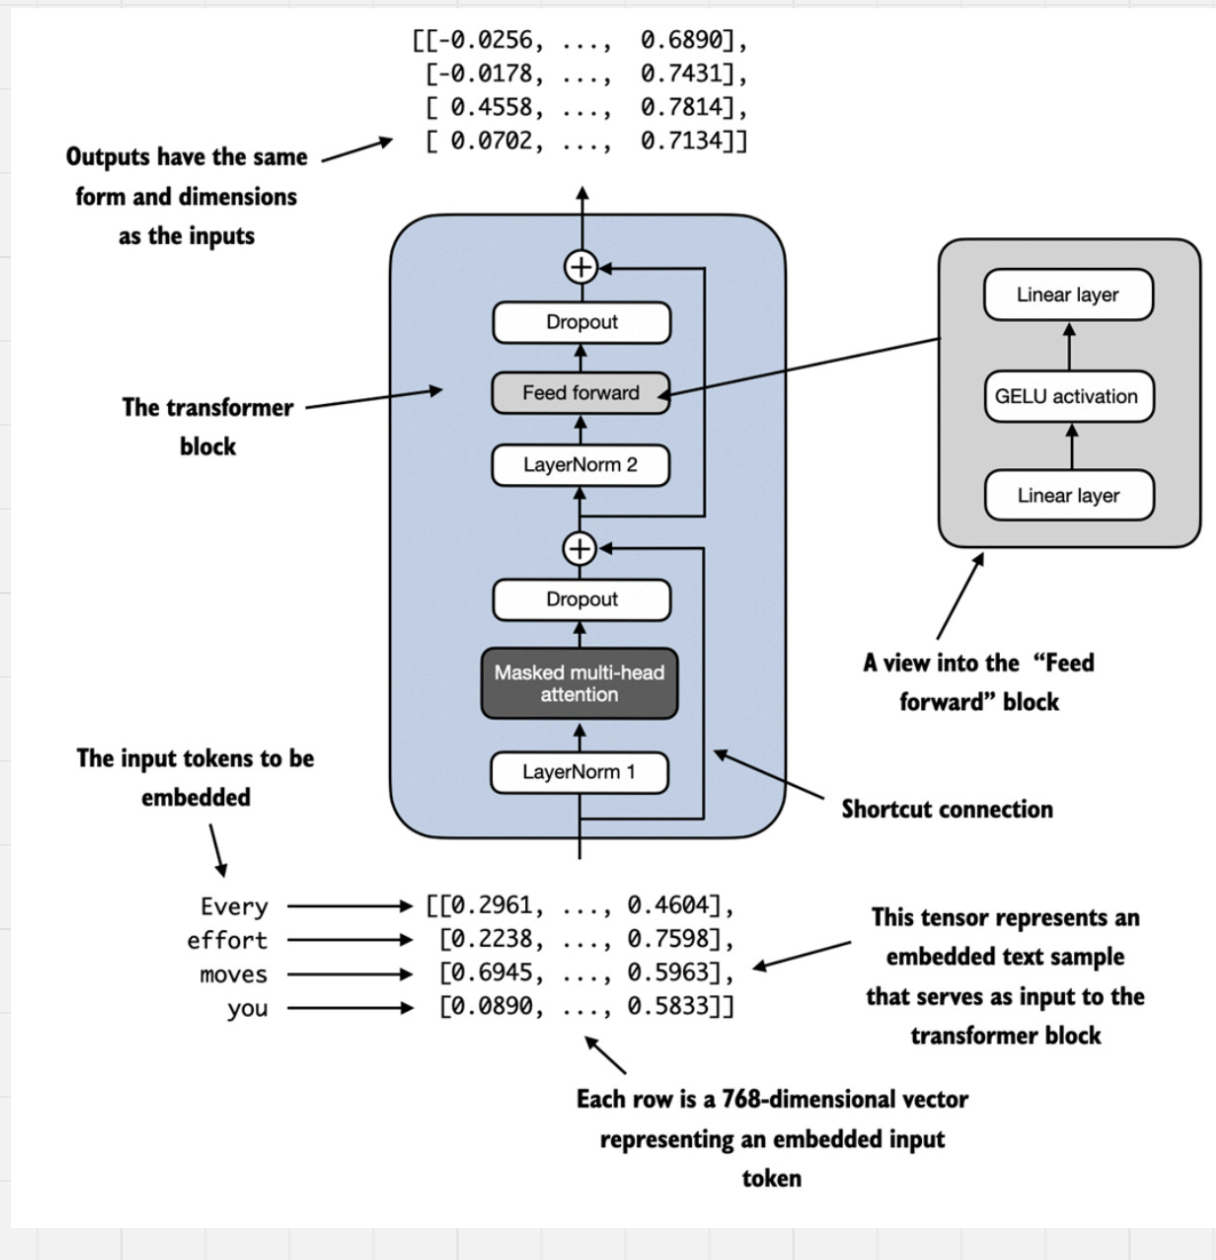


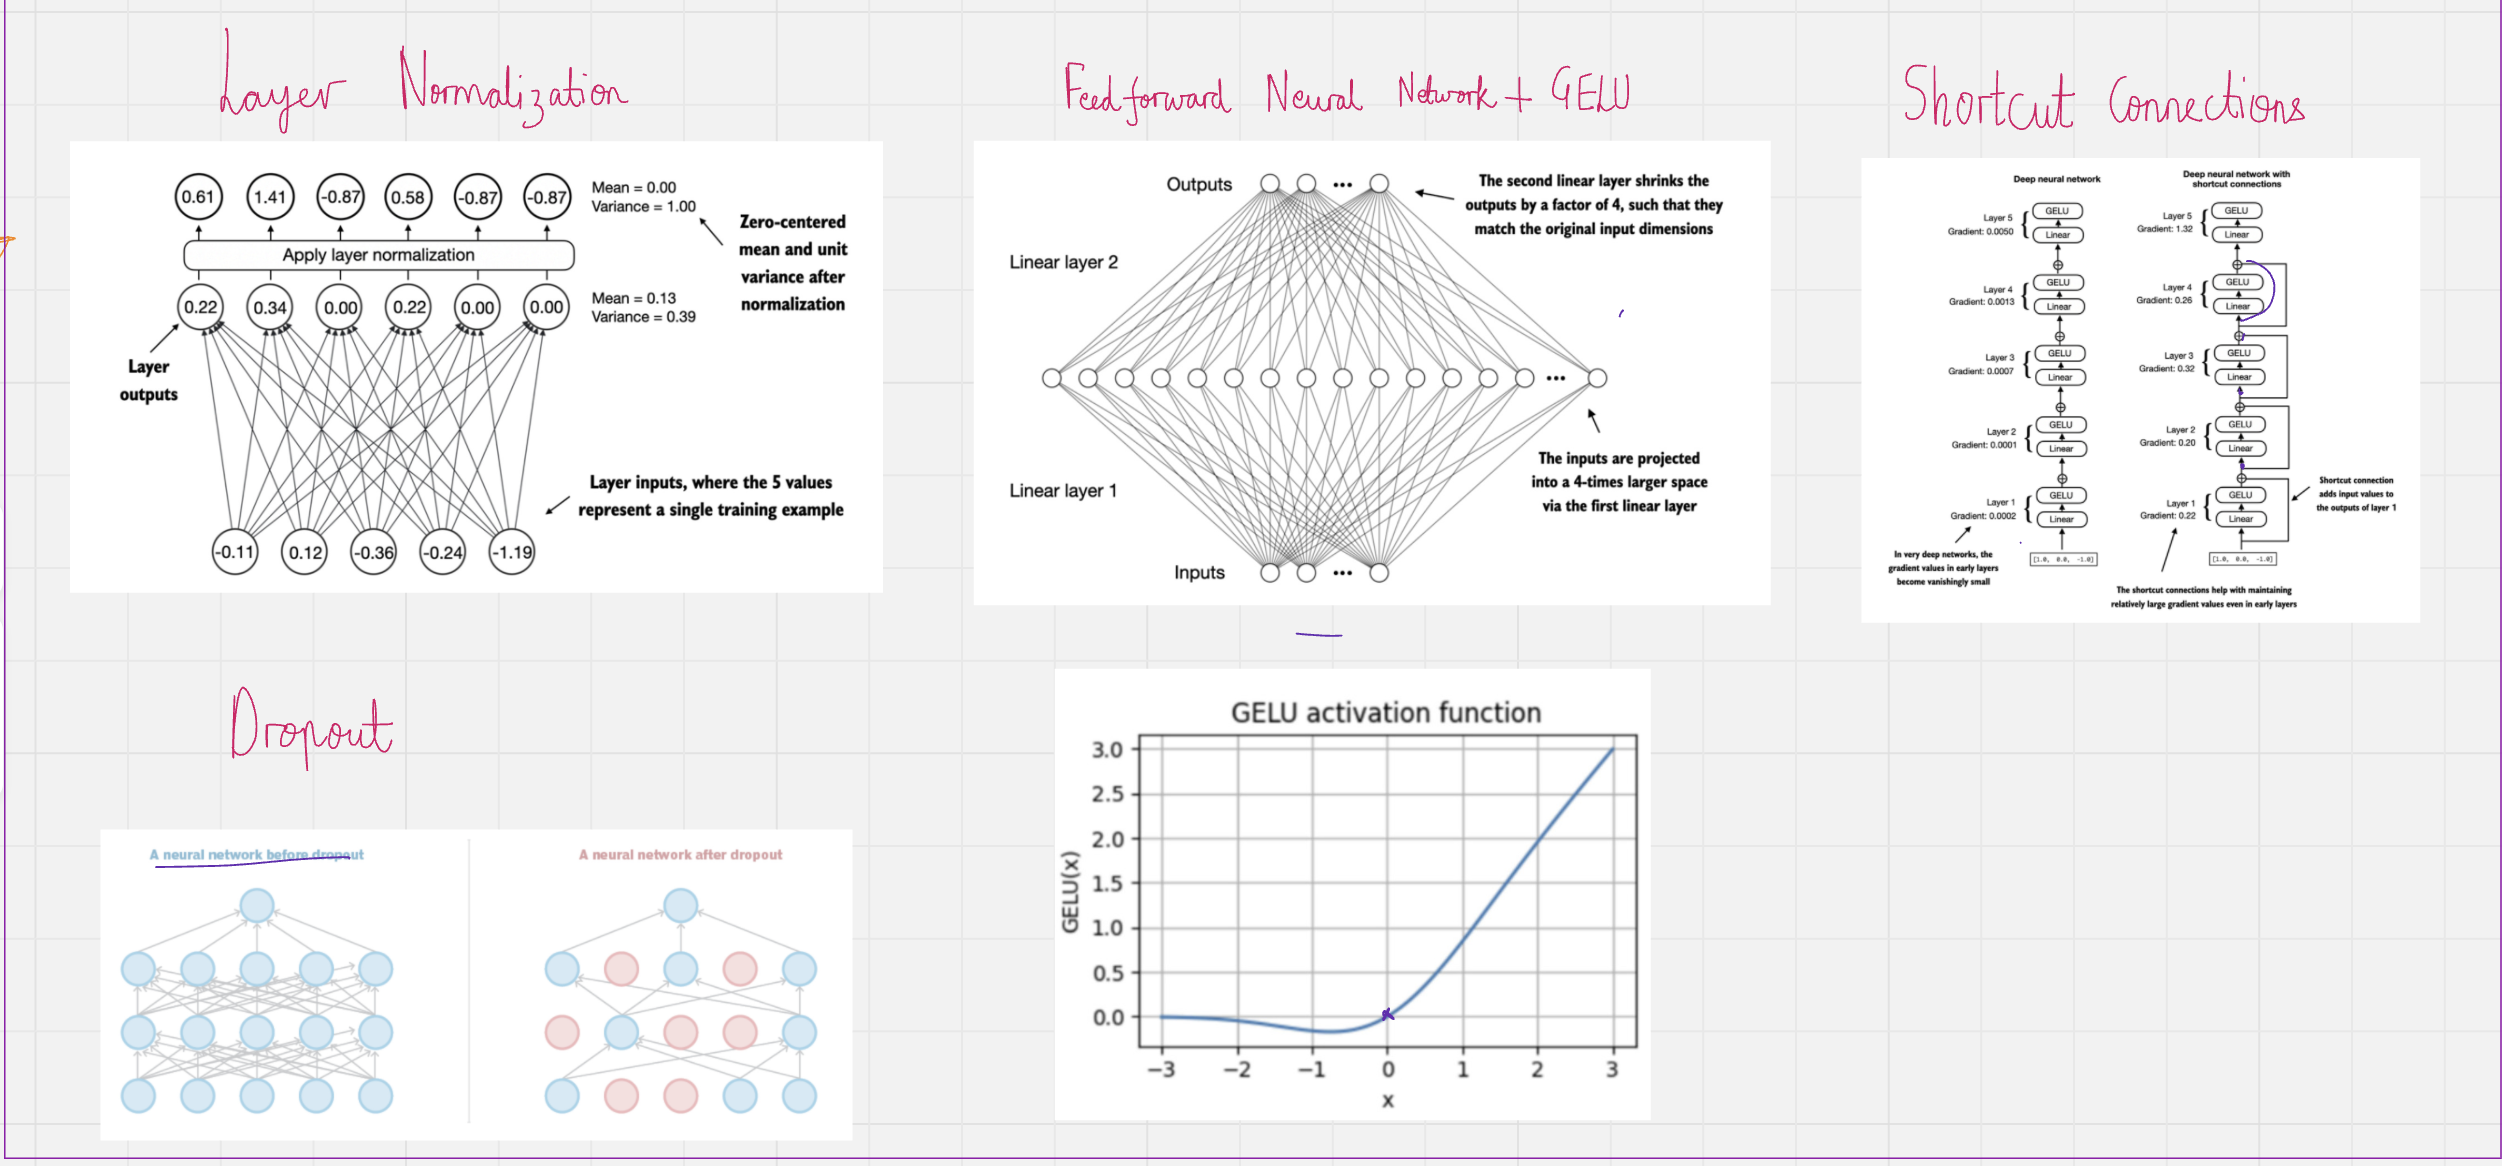

In [411]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,    # Vocabulary size
    "context_length": 1024, # Context length we are going to look 1024 number of tokens at once
    "emb_dim": 768,         # Embedding dimension
    "n_heads": 12,          # Number of attention heads
    "n_layers": 12,         # Number of layers
    "drop_rate": 0.1,       # Dropout rate
    "qkv_bias": False       # Query-Key-Value bias
}

### GPT Architecture 1: Dummy GPT Model

In [412]:
import torch
import torch.nn as nn

#  cfg --> configeration
class DummyGPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg['vocab_size'],cfg['emb_dim'])
        self.pos_emb = nn.Embedding(cfg['context_length'],cfg['emb_dim'])
        self.drop_emb = nn.Dropout(cfg['drop_rate'])

        # use placeholders for transformer block
        self.trf_block = nn.Sequential(
            *[DummyTransformerBlock(cfg) for _ in range(cfg['n_layers'])])
        
        # use placeholders for LayerNorm
        self.final_norm = DummyLayerNorm[cfg['emb_dim']]
        self.out_head = nn.Linear(
            cfg['emb_dim'],cfg['vocab_size'],bias=False
        )
    def forward(self,in_idx):
        batch_size,seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(in_idx)
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_block(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

    class DummyTransformerBlock(nn.Module):
        def __init__(self, cfg):
            super().__init__()
            # A simple placeholder

        def forward(self, x):
            # This block does nothing and just returns its input.
            return x


    class DummyLayerNorm(nn.Module):
        def __init__(self, normalized_shape, eps=1e-5):
            super().__init__()
            # The parameters here are just to mimic the LayerNorm interface.

        def forward(self, x):
            # This layer does nothing and just returns its input.
            return x

### Step 1: TOkenization

In [413]:
import tiktoken
import torch
import torch.nn as nn
tokenizer = tiktoken.get_encoding('gpt2')
batch =[]
txt1 = "Every effort moves you"
txt2 = "Every day holds a"
batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch,dim=0)
print(batch)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])


### Step 2: Create Instance of the DummyGPT Mdl


In [414]:
# torch.manual_seed(123)
# model = DummyGPTModel(GPT_CONFIG_124M)
# logits = model(batch)
# print("Output shape:", logits.shape)
# print(logits)

## GPT ARCHITECTURE PART 2: LAYER NORMALIZATION , FEEDFORWARD NEURAL NETWORK WITH GELU ACTIVATION

#### Layer Normalization

In [415]:
torch.manual_seed(123)
batch_example = torch.randn(2,5) # node
layer = nn.Sequential(nn.Linear(5,6),nn.ReLU())
out = layer(batch_example)
print(out)

# mean, variance and out_norm for the output file
mean = out.mean(dim = -1,keepdim=True)
print("Mean:\n",mean)
var = out.var(dim=-1,keepdim=True)
print("Variance:\n",var)

out_norm = (out-mean)/torch.sqrt(var)
print("Normalized layer outputs:\n", out_norm)

# mean and variance of the out_norm
mean = out_norm.mean(dim=-1, keepdim=True)
var = out_norm.var(dim=-1, keepdim=True)
print("Mean:\n", mean)
print("Variance:\n", var)

tensor([[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000],
        [0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]],
       grad_fn=<ReluBackward0>)
Mean:
 tensor([[0.1324],
        [0.2170]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[0.0231],
        [0.0398]], grad_fn=<VarBackward0>)
Normalized layer outputs:
 tensor([[ 0.6159,  1.4126, -0.8719,  0.5872, -0.8719, -0.8719],
        [-0.0189,  0.1121, -1.0876,  1.5173,  0.5647, -1.0876]],
       grad_fn=<DivBackward0>)
Mean:
 tensor([[-5.9605e-08],
        [ 1.9868e-08]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


In [416]:
# layer normalization class : alpha(X-mean/root(var)+epsilon) + beta 

class LayerNormalization(nn.Module):
    def __init__(self,emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim)) # alpha
        self.shift = nn.Parameter(torch.zeros(emb_dim)) # beta
    def forward(self,x):
        mean = x.mean(dim=-1,keepdim=True)
        var = x.var(dim=-1,keepdim=True,unbiased=False)
        norm_x = (x-mean)/torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift

In [417]:
# object of the Layer Normalization
ln = LayerNormalization(emb_dim=5)
out_ln = ln(batch_example)

mean = out_ln.mean(dim=-1, keepdim=True)
var = out_ln.var(dim=-1, unbiased=False, keepdim=True)
print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[-2.9802e-08],
        [ 0.0000e+00]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


####  GELU Activation

In [418]:
# gelu class
class GELU(nn.Module):
    def __init__(self):
        super().__init__()
    def forward(self,x):
        return 0.5*x*(1+torch.tanh(
            torch.sqrt(torch.tensor(2.0/torch.pi))*
            (x + 0.44715 * torch.pow(x,3))
        ))

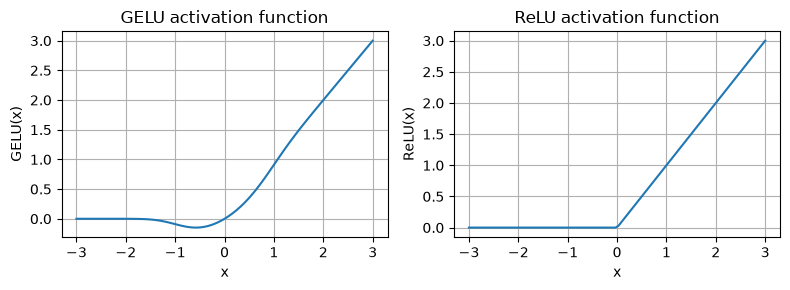

In [419]:
import matplotlib.pyplot as plt

gelu, relu = GELU(), nn.ReLU()

# Some sample data
x = torch.linspace(-3, 3, 100)
y_gelu, y_relu = gelu(x), relu(x)

plt.figure(figsize=(8, 3))
for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU", "ReLU"]), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y)
    plt.title(f"{label} activation function")
    plt.xlabel("x")
    plt.ylabel(f"{label}(x)")
    plt.grid(True)

plt.tight_layout()
plt.show()

#### FeedForward NN

In [420]:
# FeedForward NN : embed --> 4*embed ---> embed 
class FeedForward(nn.Module):
    def __init__(self,cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg['emb_dim'],4*cfg['emb_dim']),
            GELU(),
            nn.Linear(4*cfg['emb_dim'],cfg['emb_dim'])
        )
    def forward(self,x):
        return self.layers(x)

print(GPT_CONFIG_124M["emb_dim"])

768


In [421]:
ffn = FeedForward(GPT_CONFIG_124M)
x = torch.rand(2,3,768)
out= ffn(x)
print(out.shape)

torch.Size([2, 3, 768])


#### DEEPNeuralNetwork and Shortcut Connections

In [422]:
# shotcuts connections 

class ExampleDeepNeuralNetwork(nn.Module):
    def __init__(self,layer_sizes,use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[0], layer_sizes[1]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[1], layer_sizes[2]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[2], layer_sizes[3]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[3], layer_sizes[4]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[4], layer_sizes[5]), GELU())  
        ])

    def forward(self,x):
        for layer in self.layers:
            # compute the output of the current layer 
            layer_output = layer(x)
            if self.use_shortcut and x.shape == layer_output.shape:
                x = x+layer_output
            else:
                x = layer_output
        return x

In [423]:
sample_input = torch.tensor([[1., 0., -1.]])


layer_sizes = [3, 3, 3, 3, 3, 1]
torch.manual_seed(123) # specify random seed for the initial weights for reproducibility
model_without_shortcut = ExampleDeepNeuralNetwork(
layer_sizes, use_shortcut=False
)

####  Gradient Calculation

In [424]:
def print_gradients(model, x):
    # Forward pass
    output = model(x)
    target = torch.tensor([[0.]])

    # Calculate loss based on how close the target
    # and output are
    loss = nn.MSELoss()
    loss = loss(output, target)
    
    # Backward pass to calculate the gradients
    loss.backward()

    for name, param in model.named_parameters():
        if 'weight' in name:
            # Print the mean absolute gradient of the weights
            print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")

<div class="alert alert-block alert-warning">

In the preceding code, we specify a loss function that computes how close the model output
and a user-specified target (here, for simplicity, the value 0) are. 
</div>

<div class="alert alert-block alert-warning">

Then, when calling loss.backward(), PyTorch computes the loss gradient for each layer in the model. 
</div>

<div class="alert alert-block alert-warning">

We can iterate through the weight parameters via model.named_parameters(). 
</div>
<div class="alert alert-block alert-warning">

Suppose we have a 3×3 weight parameter matrix for a given layer. 

In that case, this layer will have 3×3 gradient values, and we print the mean absolute gradient of these 3×3 gradient values to
obtain a single gradient value per layer to compare the gradients between layers more
easily.
</div>

Let's now use the print_gradients function and apply it to the model without skip connections:

In [425]:
print_gradients(model_without_shortcut,sample_input)

layers.0.0.weight has gradient mean of 0.000204713229322806
layers.1.0.weight has gradient mean of 0.00012317951768636703
layers.2.0.weight has gradient mean of 0.0007344746263697743
layers.3.0.weight has gradient mean of 0.001387121039442718
layers.4.0.weight has gradient mean of 0.005026495084166527


In [426]:
sample_input = torch.tensor([[1.,0.,-1.]])
layer_sizes = [3, 3, 3, 3, 3, 1]

torch.manual_seed(123)
model_with_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes,use_shortcut=True
)
print_gradients(model_with_shortcut,sample_input)

layers.0.0.weight has gradient mean of 0.29920274019241333
layers.1.0.weight has gradient mean of 0.2749510407447815
layers.2.0.weight has gradient mean of 0.454661101102829
layers.3.0.weight has gradient mean of 0.3629586398601532
layers.4.0.weight has gradient mean of 1.763088583946228


# GPT ARCHITECTURE PART 3: CODING ATTENTION AND LINEAR LAYERS IN A TRANSFORMER BLOCK


Step 1: Shortcut connection for attention block

Step 2: Shortcut connection for feed forward block

Step 3: Add the original input back

#### MultiHeadAttention Code

In [427]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0 ,"d_out is not divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out//num_heads

        self.W_query = nn.Linear(d_in,d_out,bias=qkv_bias)
        self.W_key = nn.Linear(d_in,d_out,bias=qkv_bias)
        self.W_value = nn.Linear(d_in,d_out,bias=qkv_bias)
        self.dropout = torch.nn.Dropout(dropout)
        self.register_buffer("mask",
                            torch.triu(torch.ones(context_length,context_length),diagonal=1))
        self.out_proj = torch.nn.Linear(d_out,d_out)

    def forward(self,x):
        b,num_tokens,d_in = x.shape

        keys = self.W_key(x)  # Shape: (b, num_tokens, d_out)
        values = self.W_value(x)
        queries = self.W_query(x)

         # Reshape to split d_out into (num_heads, head_dim)
        keys = keys.view(b,num_tokens,self.num_heads,self.head_dim)
        values = values.view(b,num_tokens,self.num_heads,self.head_dim)
        queries = queries.view(b,num_tokens,self.num_heads,self.head_dim)

        # transpose the 1,2 to get b,num_heads,num_tokens,head_dim for the calculation of attn_score
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        atten_score = queries @ keys.transpose(-2,-1)
        atten_score.masked_fill(self.mask.bool()[:num_tokens,:num_tokens],-torch.inf)

        atten_weights = torch.softmax(atten_score/keys.shape[-1]**0.5,dim=-1)
        atten_weights = self.dropout(atten_weights)

        context_vec = (atten_weights@values).transpose(1,2) # transpose to get back to the originl form

        # combine the head and the head dim 
        context_vec = context_vec.contiguous().view(b,num_tokens,self.d_out)
        context_vec = self.out_proj(context_vec)

        return context_vec

#### CONFIGURATION OF THE GPT2 MODEL 124 M PARAMS

In [428]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,    # Vocabulary size
    "context_length": 256, # Context length we are going to look 1024 number of tokens at once
    "emb_dim": 768,         # Embedding dimension
    "n_heads": 12,          # Number of attention heads
    "n_layers": 12,         # Number of layers
    "drop_rate": 0.1,       # Dropout rate
    "qkv_bias": False       # Query-Key-Value bias
}

#### TransformerBlock Code

In [429]:
class TransformerBlock(nn.Module):
    def __init__(self,cfg):
        super().__init__()
        self.atten = MultiHeadAttention(
                            d_in = cfg["emb_dim"],
                            d_out = cfg["emb_dim"],
                            context_length = cfg["context_length"],
                            dropout = cfg["drop_rate"],
                            num_heads = cfg["n_heads"],
                            qkv_bias = cfg[ "qkv_bias"])
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNormalization(cfg["emb_dim"])
        self.norm2 = LayerNormalization(cfg["emb_dim"])
        self.drop_shortcuts = torch.nn.Dropout(cfg['drop_rate'])

    def forward(self,x):
        # shortcut connnection for the MultiHead Attention Block
        shortcut = x # store the x value to use it in th shotcut connections 
        x = self.norm1(x)
        x = self.atten(x)
        x = self.drop_shortcuts(x)
        x = x + shortcut

        # shortcut connection for the feed forward block 
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcuts(x)
        x = x + shortcut

        return x



In [430]:
torch.manual_seed(123)
x = torch.rand(2,4,768) #A
block = TransformerBlock(GPT_CONFIG_124M)
output = block(x)
print("Input shape:", x.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([2, 4, 768])
Output shape: torch.Size([2, 4, 768])


# ENTIRE GPT MODEL ARCHITECTURE IMPLEMENTATION

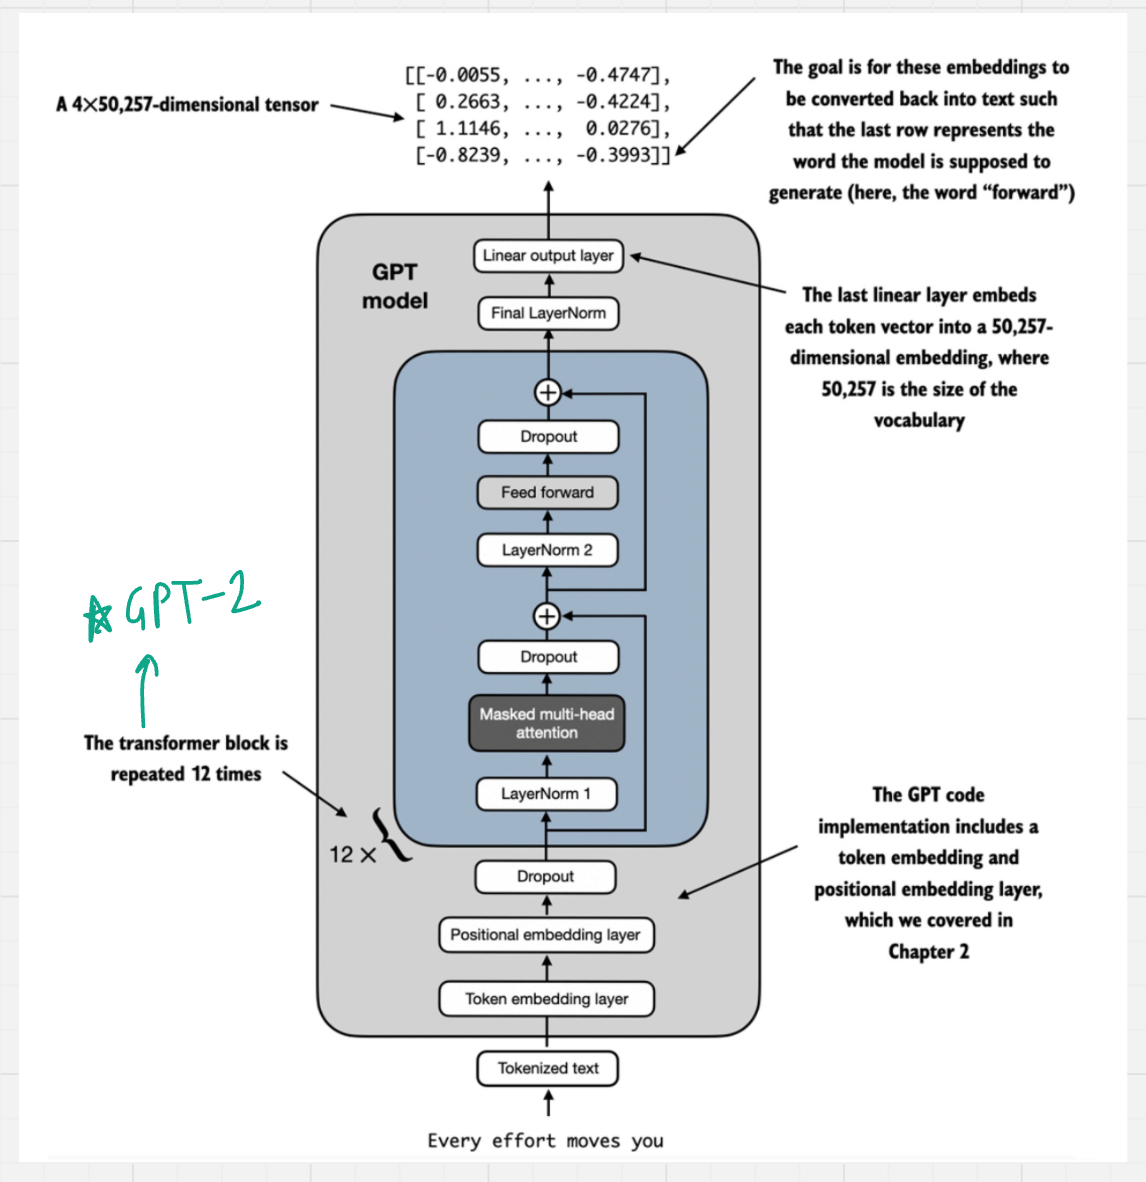

In [431]:
class GPTModel(nn.Module):
    def __init__(self,cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"],cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        self.trf_block = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])
        self.final_norm = LayerNormalization(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"],cfg["vocab_size"],bias=False
        )

    def forward(self,in_idx):
        batch_size,seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))

        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_block(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

In [432]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
out = model(batch)
print("Input batch:\n", batch)
print("\nOutput shape:", out.shape)
print(out)

Input batch:
 tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])

Output shape: torch.Size([2, 4, 50257])
tensor([[[-0.2470, -0.2055, -0.0740,  ..., -0.2773, -0.0538, -0.5261],
         [-0.4924, -0.3419, -0.7084,  ...,  0.6305, -1.1001, -0.5384],
         [ 0.4997,  0.0820,  0.5040,  ...,  0.4131,  0.1030, -0.3083],
         [-0.1439, -0.5965, -0.9118,  ...,  0.0336,  0.1396, -0.0536]],

        [[ 0.0198, -0.1136, -0.4411,  ...,  0.1261,  0.0022, -0.0531],
         [-0.6326, -0.7624, -0.9727,  ...,  0.4750,  0.0915, -0.1370],
         [ 0.6311, -0.1534, -0.0050,  ...,  0.1502,  0.1948, -0.3316],
         [-0.6101, -0.5442, -0.4180,  ..., -0.3894,  0.3958, -0.6018]]],
       grad_fn=<UnsafeViewBackward0>)


In [433]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

Total number of parameters: 162,419,712


In [434]:
print("Token embedding layer shape:", model.tok_emb.weight.shape)
print("Output layer shape:", model.out_head.weight.shape)

Token embedding layer shape: torch.Size([50257, 768])
Output layer shape: torch.Size([50257, 768])


# GENERATING TEXT FROM OUTPUT TOKENS

Current tokens

     ↓

Model predicts likelihood for every possible next token

     ↓
     
Choose the token with the highest probability

     ↓
     
Append it to the current tokens

     ↓
     
Repeat

In [435]:
def generate_new_tokens(model,idx,max_new_tokens,context_size):
    # idx is (batch, n_tokens) array of indices in the current context
    for _ in range(max_new_tokens):

        # Crop current context if it exceeds the supported context size
        # E.g., if LLM supports only 5 tokens, and the context size is 10
        # then only the last 5 tokens are used as context
        idx_cond = idx[:,-context_size:]

        # get the prediction 
        with torch.no_grad():
            logits = model(idx_cond)

        # Focus only on the last time step
        # (batch, n_tokens, vocab_size) becomes (batch, vocab_size)
        logits = logits[:,-1,:]

        # Apply softmax to get probabilities
        probas = torch.softmax(logits,dim=-1) #(batch,vocb_size)

        # Get the idx of the vocab entry with the highest probability value
        idx_next = torch.argmax(probas,dim=-1,keepdim=True)# (batch, 1)

        # Append sampled index to the running sequence
        idx = torch.cat((idx,idx_next),dim=-1) #(batch, n_tokens+1)

    return idx
        

In [436]:
start_context = "Hello, I am"
encoded = tokenizer.encode(start_context)
print("encoded:", encoded)
encoded_tensor = torch.tensor(encoded).unsqueeze(0) # (batch,num_tokens) --> [4]--> [1,4]
print("encoded_tensor.shape:", encoded_tensor.shape)

encoded: [15496, 11, 314, 716]
encoded_tensor.shape: torch.Size([1, 4])


In [437]:
model.eval()

out = generate_new_tokens(model=model,
                          idx=encoded_tensor,
                          max_new_tokens=6,
                          context_size=GPT_CONFIG_124M['context_length'])
print("Output: ",out)
print("output_length: ",len(out[0]))

Output:  tensor([[15496,    11,   314,   716, 13240, 11381, 20180, 25405, 17434, 17853]])
output_length:  10


In [438]:
decoded_text = tokenizer.decode(out.squeeze(0).tolist())
print(decoded_text)

Hello, I am Laur inhabElementم refres Rex


# Evaluating Generative Text Models 

### GPT Model class we coded earlier

In [439]:
class GPTModel(nn.Module):
    def __init__(self,cfg):
        super().__init__()

        self.tok_emb = nn.Embedding(cfg['vocab_size'],cfg['emb_dim'])
        self.pos_emb = nn.Embedding(cfg['context_length'],cfg['emb_dim'])
        self.drop_emb = nn.Dropout(cfg['drop_rate'])

        self.trf_block = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg['n_layers'])])
        self.final_norm = LayerNormalization(cfg['emb_dim'])
        self.out_head = nn.Linear(
            cfg['emb_dim'],cfg['vocab_size'],bias = False
        )
    def forward(self,in_idx):
        batch_size,seq_len = in_idx.shape
        tok_embed = self.tok_emb(in_idx)
        pos_embed = self.pos_emb(torch.arange(seq_len,device= in_idx.device))
        x = tok_embed+pos_embed
        x = self.drop_emb(x)
        x = self.trf_block(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits
        

### Using GPT to generate text

In [440]:
# use GPT to generate text

import torch

GPT_CONFIG_124M = {
    "vocab_size": 50257,   # Vocabulary size
    "context_length": 256, # Shortened context length (orig: 1024)
    "emb_dim": 768,        # Embedding dimension
    "n_heads": 12,         # Number of attention heads
    "n_layers": 12,        # Number of layers
    "drop_rate": 0.1,      # Dropout rate
    "qkv_bias": False      # Query-key-value bias
}

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.eval();  # Disable dropout during inference

We reduce the context length (context_length) of only 256 tokens to reduce the computational resource requirements for training the model, whereas the original 124 million parameter GPT-2 model used 1024 tokens

This is so that more readers will be able to follow and execute the code examples on their laptop computer

Next, we use the generate_text_simple function from the previous chapter to generate text.

In addition, we define two convenience functions, text_to_token_ids and token_ids_to_text, for converting between token and text representations that we use throughout this chapter

In [441]:
import tiktoken

tokenizer = tiktoken.get_encoding('gpt2')
def text_to_token(text,tokenizer):
    encoded = tokenizer.encode(text,allowed_special={'<|endoftext|>'})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0) # add batch dim
    return encoded_tensor
def token_to_text(token_ids,tokenizer):
    flat = token_ids.squeeze(0) # remove batch dim
    return tokenizer.decode(flat.tolist())

start_context = "Every effort moves you"

token_ids = generate_new_tokens(model=model,
                               idx =text_to_token(start_context,tokenizer),
                               max_new_tokens=10,
                               context_size = GPT_CONFIG_124M["context_length"]
                               )

print("Output text:\n", token_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you rentingetic minion mobilized Macicone warrantyuler anim supra


### Calculating the text generation loss: cross-entropy and perplexity

In [442]:
inputs = torch.tensor([[16833, 3626, 6100],   # ["every effort moves",
                       [40,    1107, 588]])   #  "I really like"]

targets = torch.tensor([[3626, 6100, 345  ],  # [" effort moves you",
                        [1107,  588, 11311]]) #  " really like chocolate"]

In [443]:
with torch.no_grad():
    logits = model(inputs)
probas = torch.softmax(logits,dim=-1)
print(probas)
print(probas.shape)

tensor([[[2.6514e-05, 1.1089e-05, 1.6060e-05,  ..., 2.4843e-05,
          7.0991e-06, 1.5913e-05],
         [1.0235e-05, 9.5021e-06, 7.6700e-06,  ..., 4.0126e-05,
          5.8216e-06, 1.0366e-05],
         [3.1604e-05, 9.0624e-06, 1.6100e-05,  ..., 3.5131e-05,
          1.3888e-05, 1.1462e-05]],

        [[2.0680e-05, 1.7201e-05, 1.5975e-05,  ..., 1.0935e-05,
          5.3845e-05, 1.0590e-05],
         [7.1535e-06, 1.7456e-05, 9.1769e-06,  ..., 3.4297e-05,
          9.2104e-06, 1.4940e-05],
         [3.1135e-05, 3.1383e-05, 3.9250e-05,  ..., 6.9278e-06,
          5.5382e-05, 1.1918e-05]]])
torch.Size([2, 3, 50257])


**As discussed in the previous chapter, we can apply the argmax function to convert the probability scores into predicted token IDs.**

**The softmax function above produced a 50,257-dimensional vector for each token; the argmax function returns the position of the highest probability score in this vector, which is the predicted token ID for the given token.**

**Since we have 2 input batches with 3 tokens each, we obtain 2 by 3 predicted token IDs:**

In [444]:
token_ids = torch.argmax(probas,dim=-1,keepdim=True)
print("Token_Ids:",token_ids)

Token_Ids: tensor([[[36195],
         [16031],
         [42826]],

        [[25050],
         [ 7822],
         [16637]]])


In [445]:
print(f"Targets batch 1: {token_to_text(targets[0], tokenizer)}")
print(f"Outputs batch 1: {token_to_text(token_ids[0].flatten(), tokenizer)}")

Targets batch 1:  effort moves you
Outputs batch 1: lif savesNetflix


## Cross-entropy loss --> - log(loss)

In [446]:
logits

tensor([[[ 0.4529, -0.4189, -0.0485,  ...,  0.3877, -0.8649, -0.0577],
         [-0.4993, -0.5736, -0.7878,  ...,  0.8669, -1.0635, -0.4866],
         [ 0.6276, -0.6215, -0.0469,  ...,  0.7334, -0.1946, -0.3866]],

        [[ 0.2028,  0.0186, -0.0553,  ..., -0.4344,  1.1598, -0.4664],
         [-0.8531,  0.0390, -0.6040,  ...,  0.7143, -0.6004, -0.1167],
         [ 0.6158,  0.6238,  0.8474,  ..., -0.8870,  1.1918, -0.3445]]])

In [447]:
logits.shape # inputs

torch.Size([2, 3, 50257])

In [448]:
targets.shape

torch.Size([2, 3])

In [449]:
logits_flat = logits.flatten(0,1)
targets_flat = targets.flatten()

print("Flattened logits:", logits_flat.shape)
print("Flattened targets:", targets_flat.shape)

Flattened logits: torch.Size([6, 50257])
Flattened targets: torch.Size([6])


In [450]:
loss = torch.nn.functional.cross_entropy(logits_flat,targets_flat)
print(loss)

tensor(10.9958)


## ₹Perplexity₹ : The perplexity is simply the exponential of the cross-entropy loss
### **A concept related to the cross-entropy loss is the perplexity of an LLM.**


In [451]:
perplexity = torch.exp(loss)
print(perplexity)

tensor(59620.8672)


<div class="alert alert-block alert-warning">
Perplexity is often considered more interpretable because it can be understood as the effective vocabulary size that the model is uncertain about at each step (in the example above, that'd be 48,725 words or tokens).
</div>

<div class="alert alert-block alert-warning">
In other words, perplexity provides a measure of how well the probability distribution predicted by the model matches the actual distribution of the words in the dataset.
</div>

<div class="alert alert-block alert-warning">
Similar to the loss, a lower perplexity indicates that the model predictions are closer to the actual distribution
</div>

# LLM Performance On Real DataSet

## Tokenize and Break the data into input-target variable 

In [452]:
import os 
import urllib.request

file_path = 'GPT_Tokenizer/the-verdict.txt'
url = "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch02/01_main-chapter-code/the-verdict.txt"

if not os.path.exists(file_path):
    with urllib.request.urlopen(url) as response:
        text_data = response.read().decode('utf-8')
    with open(file_path, "w", encoding="utf-8") as file:
        file.write(text_data)
else:
    with open(file_path, "r", encoding="utf-8") as file:
        text_data = file.read()  

In [453]:
# first 100 chars 
print(text_data[:100])
# Last 100 characters
print(text_data[-99:])

I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no g
it for me! The Strouds stand alone, and happen once--but there's no exterminating our kind of art."


In [454]:
# byte pair encoding 
import tiktoken 
tokenizer = tiktoken.get_encoding('gpt2')

In [455]:
total_chars = len(text_data)
total_tokens = len(tokenizer.encode(text_data))

print("Characters:", total_chars)
print("Tokens:", total_tokens)

Characters: 20479
Tokens: 5145


## Dataset & Dataloader Class --> load the dataset and dataloader

In [456]:
from torch.utils.data import Dataset,DataLoader
import tiktoken

class GPTDataset(Dataset):
    def __init__(self,txt,tokenizer,max_length,stride):
        self.input_ids = []
        self.target_ids = []

        token_ids = tokenizer.encode(txt,allowed_special={"<|endoftext|>"})
        # to divide the data into the input and target --> using the sliding windiow --> to chunk the book 
        for i in range(0,len(token_ids)-max_length,stride):
            input_chunk = token_ids[i:i+max_length]
            target_chunk = token_ids[i+1:i+max_length+1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))
    def __len__(self):
        return len(self.input_ids)
    def __getitem__(self,idx):
        return self.input_ids[idx],self.target_ids[idx]
        

def create_dataloader_v1(txt, batch_size=4, max_length=256, 
                         stride=128, shuffle=True, drop_last=True,
                         num_workers=0):

    # Initialize the tokenizer
    tokenizer = tiktoken.get_encoding("gpt2")

    # dataset-create
    dataset = GPTDataset(txt, tokenizer, max_length, stride)

    # Create dataloader
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )

    return dataloader

In [457]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,   # Vocabulary size
    "context_length": 256, # Shortened context length (orig: 1024)
    "emb_dim": 768,        # Embedding dimension
    "n_heads": 12,         # Number of attention heads
    "n_layers": 12,        # Number of layers
    "drop_rate": 0.1,      # Dropout rate
    "qkv_bias": False      # Query-key-value bias
}

## Train-Validation Ratio of the Dataset

In [458]:
# train - val ratio 

train_ratio = 0.90 
split_idx = int(train_ratio*len(text_data))

train_data = text_data[:split_idx]
val_data = text_data[split_idx:]

torch.manual_seed(123)

train_loader = create_dataloader_v1(train_data,
                                    batch_size=2,
                                    max_length=GPT_CONFIG_124M["context_length"],
                                    stride = GPT_CONFIG_124M["context_length"],
                                    drop_last=True,
                                    shuffle = True,
                                    num_workers=0
)

val_loader = create_dataloader_v1(val_data,
                                batch_size=2,
                                max_length=GPT_CONFIG_124M["context_length"],
                                stride=GPT_CONFIG_124M["context_length"],
                                drop_last=False,
                                shuffle=False,
                                num_workers=0
)

In [459]:
# Sanity check

if total_tokens * (train_ratio) < GPT_CONFIG_124M["context_length"]:
    print("Not enough tokens for the training loader. "
          "Try to lower the `GPT_CONFIG_124M['context_length']` or "
          "increase the `training_ratio`")

if total_tokens * (1-train_ratio) < GPT_CONFIG_124M["context_length"]:
    print("Not enough tokens for the validation loader. "
          "Try to lower the `GPT_CONFIG_124M['context_length']` or "
          "decrease the `training_ratio`")

In [460]:
print("Train loader:")
for x, y in train_loader:
    print(x.shape, y.shape)

print("\nValidation loader:")
for x, y in val_loader:
    print(x.shape, y.shape)

print(len(train_loader))
print(len(val_loader))

Train loader:
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])

Validation loader:
torch.Size([2, 256]) torch.Size([2, 256])
9
1


In [461]:
# checking the train_tokens & validation_token --> total_tokens
train_tokens = 0
for input_batch, target_batch in train_loader:
    train_tokens += input_batch.numel()

val_tokens = 0
for input_batch, target_batch in val_loader:
    val_tokens += input_batch.numel()

print("Training tokens:", train_tokens)
print("Validation tokens:", val_tokens)
print("All tokens:", train_tokens + val_tokens)

Training tokens: 4608
Validation tokens: 512
All tokens: 5120


## GPT MODEL 

In [462]:
# layer normalization class : alpha(X-mean/root(var)+epsilon) + beta 

class LayerNormalization(nn.Module):
    def __init__(self,emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim)) # alpha
        self.shift = nn.Parameter(torch.zeros(emb_dim)) # beta
    def forward(self,x):
        mean = x.mean(dim=-1,keepdim=True)
        var = x.var(dim=-1,keepdim=True,unbiased=False)
        norm_x = (x-mean)/torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift

In [463]:
# gelu class
class GELU(nn.Module):
    def __init__(self):
        super().__init__()
    def forward(self,x):
        return 0.5*x*(1+torch.tanh(
            torch.sqrt(torch.tensor(2.0/torch.pi))*
            (x + 0.44715 * torch.pow(x,3))
        ))

In [464]:
# FeedForward NN : embed --> 4*embed ---> embed 
class FeedForward(nn.Module):
    def __init__(self,cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg['emb_dim'],4*cfg['emb_dim']),
            GELU(),
            nn.Linear(4*cfg['emb_dim'],cfg['emb_dim'])
        )
    def forward(self,x):
        return self.layers(x)

print(GPT_CONFIG_124M["emb_dim"])

768


In [465]:
class TransformerBlock(nn.Module):
    def __init__(self,cfg):
        super().__init__()
        self.atten = MultiHeadAttention(
                            d_in = cfg["emb_dim"],
                            d_out = cfg["emb_dim"],
                            context_length = cfg["context_length"],
                            dropout = cfg["drop_rate"],
                            num_heads = cfg["n_heads"],
                            qkv_bias = cfg[ "qkv_bias"])
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNormalization(cfg["emb_dim"])
        self.norm2 = LayerNormalization(cfg["emb_dim"])
        self.drop_shortcuts = torch.nn.Dropout(cfg['drop_rate'])

    def forward(self,x):
        # shortcut connnection for the MultiHead Attention Block
        shortcut = x # store the x value to use it in th shotcut connections 
        x = self.norm1(x)
        x = self.atten(x)
        x = self.drop_shortcuts(x)
        x = x + shortcut

        # shortcut connection for the feed forward block 
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcuts(x)
        x = x + shortcut

        return x


In [466]:
class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        
        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])
        
        self.final_norm = LayerNormalization(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds  # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

In [467]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.eval();  # Disable dropout during inference

### Loss during the model --> cross-entropy-loss

In [468]:
def calc_loss_batch(input_batch,target_batch,model,device):
    input_batch,target_batch = input_batch.to(device),target_batch.to(device)
    logits = model(input_batch) # model initailization 
    loss = torch.nn.functional.cross_entropy(logits.flatten(0,1),target_batch.flatten())
    return loss

def calc_loss_loader(data_loader, model, device, num_batches=None):
    total_loss = 0.
    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        # Reduce the number of batches to match the total number of batches in the data loader
        # if num_batches exceeds the number of batches in the data loader
        num_batches = min(num_batches, len(data_loader))
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
        else:
            break
    return total_loss / num_batches

In [469]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Note:
# Uncommenting the following lines will allow the code to run on Apple Silicon chips, if applicable,
# which is approximately 2x faster than on an Apple CPU (as measured on an M3 MacBook Air).
# However, the resulting loss values may be slightly different.

if torch.cuda.is_available():
   device = torch.device("cuda")
elif torch.backends.mps.is_available():
   device = torch.device("mps")
else:
   device = torch.device("cpu")

print(f"Using {device} device.")


model.to(device) # no assignment model = model.to(device) necessary for nn.Module classes


torch.manual_seed(123) # For reproducibility due to the shuffling in the data loader

with torch.no_grad(): # Disable gradient tracking for efficiency because we are not training, yet
    train_loss = calc_loss_loader(train_loader, model, device)
    val_loss = calc_loss_loader(val_loader, model, device)

print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Using mps device.
Training loss: 10.98706669277615
Validation loss: 10.981828689575195


## Training Loop in the LLM

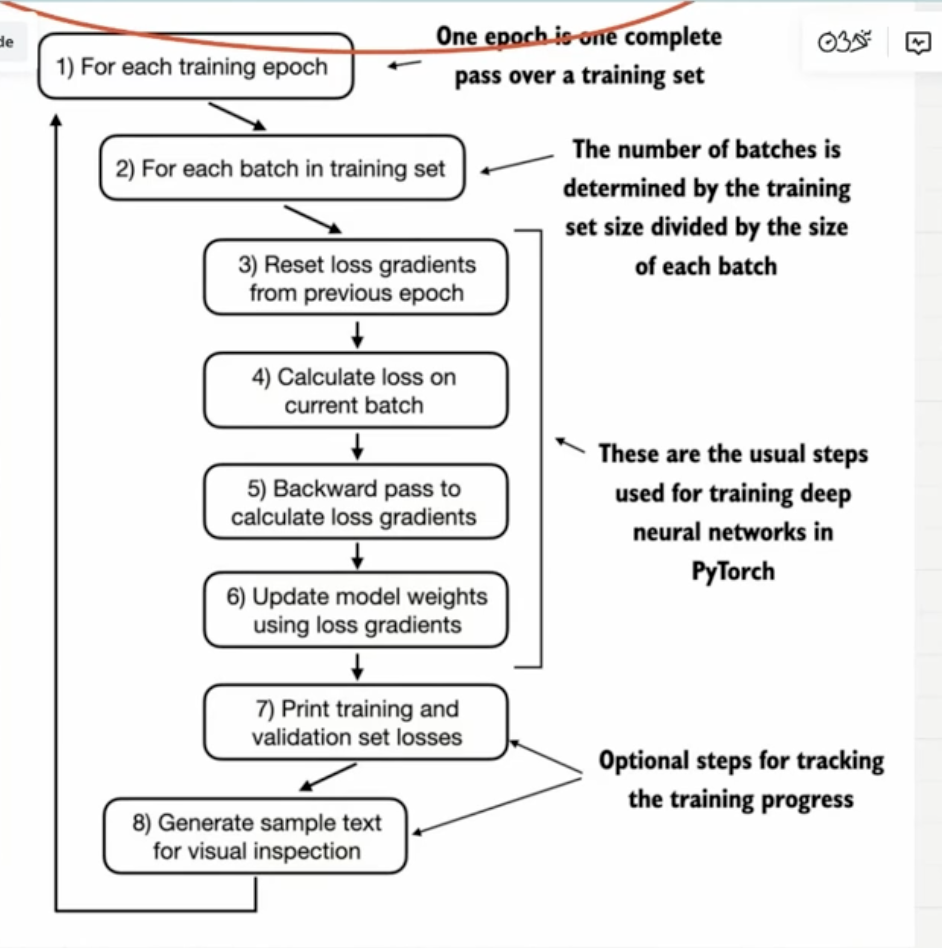
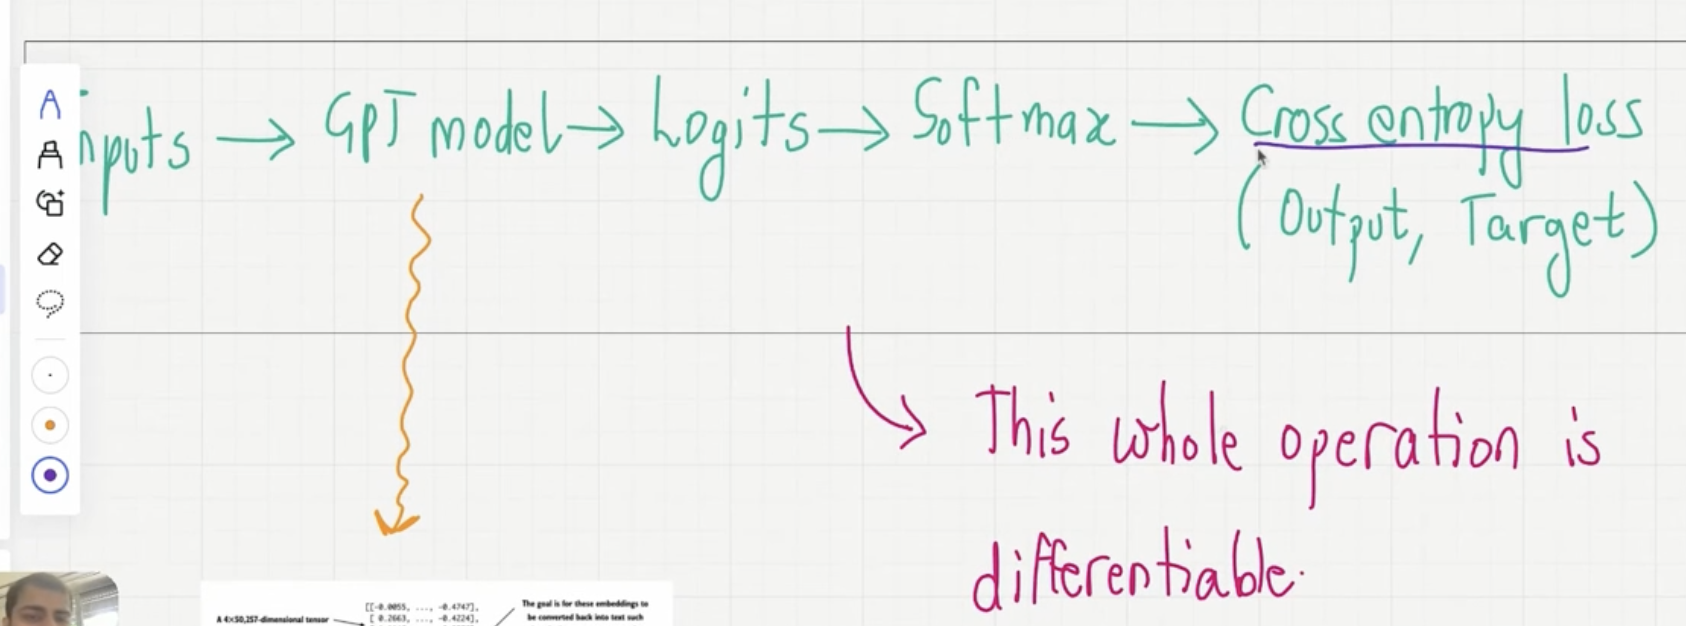

In [470]:
def evaluation_model(model,train_loader,val_loader,device,eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader,model,device,num_batches=eval_iter)
        val_loss = calc_loss_loader(train_loader,model,device,num_batches=eval_iter)
    model.train()
    return train_loss,val_loss
    

In [471]:
def train_model_simple(model,train_loader,val_loader,optimizer,device,num_epochs,eval_freq,
                      eval_iter,start_context,tokenizer):

    # initalize lists to track losses and tokens seen
    train_losses,val_losses,track_tokens_seen = [],[],[]
    tokens_seen , global_step = 0,-1

    # main traiining loop 
    for epoch in range(num_epochs):
        model.train()

        for input_batch,target_batch in train_loader:
            optimizer.zero_grad()
            loss = calc_loss_batch(input_batch,target_batch,model,device)
            loss.backward()
            optimizer.step()
            tokens_seen += input_batch.numel()  # Returns the total number of elements (or tokens) in the input_batch.
            global_step+=1

            # optimizer evaluation step
            if global_step % eval_freq ==0:
                train_loss,val_loss = evaluation_model(model,
                                                train_loader,
                                                val_loader,
                                                device,eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_loss)

                track_tokens_seen.append(tokens_seen)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")

            # print a sample text after each epoch 
            generate_and_print_samples(model,tokenizer,device,start_context)
    return train_losses,val_losses,track_tokens_seen

In [481]:
model.pos_emb.weight.shape

torch.Size([256, 768])

In [487]:
def generate_and_print_samples(model,tokenizer,device,start_context):
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded = text_tot_token(start_context, tokenizer).to(device)

    with torch.no_grad():
        token_ids = generate_new_tokens(model=model,idx=encoded,
                                        max_new_tokens=50,
                                        context_size=context_size)
        decoded_text = token_to_text(token_ids,tokenizer)
        print(decoded_text.replace("\n"," ")) 
        model.train()

In [482]:
# Note:
# Uncomment the following code to calculate the execution time
import time
start_time = time.time()

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0004, weight_decay=0.1)

num_epochs = 25
train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context="Every effort moves you", tokenizer=tokenizer
)


end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")
    

Ep 1 (Step 000000): Train loss 9.803, Val loss 9.769
Every effort moves you,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Every effort moves you,.                                                
Every effort moves you,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Every effort moves you,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Every effort moves you,,,,,,,,,,,,,,,,,,,,,,,,,,,,, the,,,,,,,,,,,,,,,,,,,,
Ep 1 (Step 000005): Train loss 7.940, Val loss 8.202
Every effort moves you the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the
Every effort moves you, the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the
Every effort moves you,.                                                
Every effo

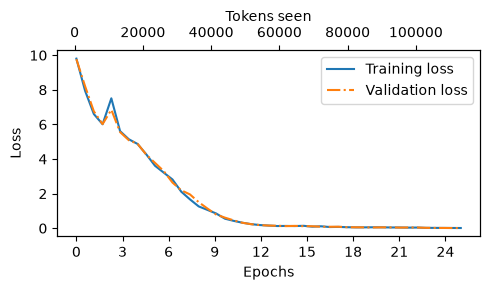

In [478]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(5, 3))

    # Plot training and validation loss against epochs
    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))  # only show integer labels on x-axis

    # Create a second x-axis for tokens seen
    ax2 = ax1.twiny()  # Create a second x-axis that shares the same y-axis
    ax2.plot(tokens_seen, train_losses, alpha=0)  # Invisible plot for aligning ticks
    ax2.set_xlabel("Tokens seen")

    fig.tight_layout()  # Adjust layout to make room
    plt.savefig("loss-plot.pdf")
    plt.show()

epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

# DECODING STRATEGIES TO CONTROL RANDOMNESS
-  **Temperature Sampling**
-  **Top K sampling**

In [484]:
model.to("cpu")
model.eval()

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(256, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (atten): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=False)
        (W_key): Linear(in_features=768, out_features=768, bias=False)
        (W_value): Linear(in_features=768, out_features=768, bias=False)
        (dropout): Dropout(p=0.1, inplace=False)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNormalization()
      (norm2): LayerNormalization()
      (drop_shortcuts): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (atten): MultiHeadAttention(
        (W_que

In [486]:
tokenizer = tiktoken.get_encoding("gpt2")

token_ids = generate_new_tokens(model=model,
                               idx=text_to_token("Every Effort moves you",tokenizer),
                                max_new_tokens=25,
                                context_size=GPT_CONFIG_124M["context_length"]
                               )
print("Output Text: ",token_to_text(token_ids,tokenizer))

Output Text:  Every Effort moves you know mighty up-stream stroke. The mere outline of the frame called up all Gisburn's past!

He


### Temperature Sampling & Top-K Sampling

In [488]:
vocab = { 
    "closer": 0,
    "every": 1, 
    "effort": 2, 
    "forward": 3,
    "inches": 4,
    "moves": 5, 
    "pizza": 6,
    "toward": 7,
    "you": 8,
}

inverse_vocab = {v:k for k,v in vocab.items()}

# assume the LLM is given the start context "every effort moves you" and generates 
#the following next-token logits:
next_token_logits = torch.tensor(
[4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]
)

# Deterministic Process for the next token calculation 
probas = torch.softmax(next_token_logits,dim=0)
next_token_id = torch.argmax(probas).item()
print(inverse_vocab[next_token_id])


forward


<div class="alert alert-block alert-success">

### To implement a probabilistic sampling process, we can now replace the argmax with the multinomial function in PyTorch:
</div>

In [493]:
torch.manual_seed(123)
next_token_id = torch.multinomial(probas,num_samples=1).item() # --> without items it returns list
print(next_token_id)
print(inverse_vocab[next_token_id])

3
forward


<div class="alert alert-block alert-success">

The printed output is "forward" just like before. What happened? The multinomial function samples the next token proportional to its probability score.
</div>
<div class="alert alert-block alert-success">

In other words, "forward" is still the most likely token and will be selected by multinomial most of the time but not all the time.
</div>
To illustrate this, let's implement a function that repeats this sampling 1000 times:

In [500]:
def print_sampled_tokens(probas):
    torch.manual_seed(123)
    sample = [torch.multinomial(probas,num_samples=1).item() for i in range(1000)]
    sampled_ids = torch.bincount(torch.tensor(sample))
    for i , freq in enumerate(sampled_ids):
        print(f"{freq} x {inverse_vocab[i]}")

print_sampled_tokens(probas)

73 x closer
0 x every
0 x effort
582 x forward
2 x inches
0 x moves
0 x pizza
343 x toward


As we can see based on the output, the word "forward" is sampled most of the time (582 out of 1000 times), but other tokens such as "closer", "inches", and "toward" will also be sampled some of the time.

This means that if we replaced the argmax function with the multinomial function inside the generate_and_print_sample function, the LLM would sometimes generate texts such as "every effort moves you toward", "every effort moves you inches", and "every effort moves you closer" instead of "every effort moves you forward".

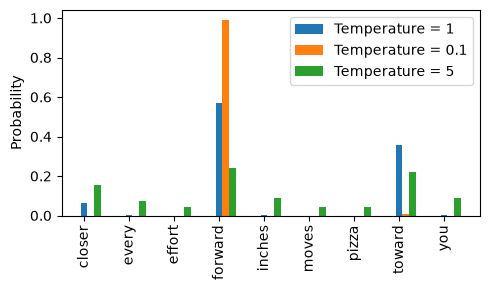

In [504]:
# softmax with temperature
def softmax_with_temperature(logits,temperature):
    scaled_logits = logits/temperature
    return torch.softmax(scaled_logits,dim=0)

# next tokens logits 
next_token_logits = torch.tensor(
[4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]
)

# temp values 
temperature = [1,0.1,5]

# calculate scaled prob 
scaled_probas = [softmax_with_temperature(next_token_logits,T) for T in temperature]

# Plotting
x = torch.arange(len(vocab))
bar_width = 0.15

fig, ax = plt.subplots(figsize=(5, 3))
for i, T in enumerate(temperature):
    rects = ax.bar(x + i * bar_width, scaled_probas[i], bar_width, label=f'Temperature = {T}')

ax.set_ylabel('Probability')
ax.set_xticks(x)
ax.set_xticklabels(vocab.keys(), rotation=90)
ax.legend()

plt.tight_layout()
plt.savefig("temperature-plot.pdf")
plt.show()

### DECODING STRATEGY 2: Top-k sampling

top-k sampling, which, when combined with probabilistic sampling and temperature scaling, can improve the text generation results.

In top-k sampling, we can restrict the sampled tokens to the top-k most likely tokens and exclude all other tokens from the selection process by masking their probability scores.



In [505]:
top_k = 3
top_logits , top_pos = torch.topk(next_token_logits,top_k)
print("Top logits:", top_logits)
print("Top positions:", top_pos)

Top logits: tensor([6.7500, 6.2800, 4.5100])
Top positions: tensor([3, 7, 0])


In [507]:
# new_logits 
new_logits = torch.where(
    condition = next_token_logits<top_logits[-1],
    input = torch.tensor(float("-inf")),
    other=next_token_logits
)
print(new_logits)

topk_probas = torch.softmax(new_logits,dim=0)
print(topk_probas)

tensor([4.5100,   -inf,   -inf, 6.7500,   -inf,   -inf,   -inf, 6.2800,   -inf])
tensor([0.0615, 0.0000, 0.0000, 0.5775, 0.0000, 0.0000, 0.0000, 0.3610, 0.0000])


### Merge Temperature Scaling and Top-k sampling

<div class="alert alert-block alert-success">
    
Step 1: For-loop is the same as before: Get logits, and only focus on last time step
    

ef 
Step 2: In this new section, we filter logits with top_k sampling


Step 3: This is the new section where we apply temperature scaling

Step 4: Carry out greedy next-token selection as before when temperature scaling is disabled

Step 5: Stop generating early if end-of-sequence token is encountered and eos_id is specified
</div>

In [526]:
def generate(model,idx,max_new_tokens,context_length,temperature=0.0,top_k=None,eos_id=None):
    # get logits 
    for _ in range(max_new_tokens):
        idx_cond = idx[:,-context_length:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:,-1,:]

        # new filter logits with top-k sampling 
        if top_k is not None:
            # keep only top k values
            top_logits, _ = torch.topk(logits,top_k)
            print(f"Top_Logits:",top_logits)
            min_val = top_logits[:,-1]
            logits = torch.where(logits<min_val,torch.tensor(float("-inf")).to(logits.device),logits)

        # new apply temperature scaling

        if temperature>0.0:
            logits = logits/temperature

            # apply softmax 
            probas = torch.softmax(logits,dim=-1) #(batch_size,context_len)

            # sample from the distribution 
            idx_next = torch.multinomial(probas,num_samples=1) #(batch_size,1)

        else:
            idx_next = torch.argmax(logits,dim=-1,keepdim=True)

        if idx_next==eos_id:
            break

        idx = torch.cat((idx,idx_next),dim=1) # (batch_size,num_tokens+1)

    return idx

In [527]:
torch.manual_seed(123)

token_ids = generate(
    model=model,
    idx=text_to_token("Every effort moves you", tokenizer),
    max_new_tokens=15,
    context_length=GPT_CONFIG_124M["context_length"],
    top_k=25,
    temperature=1.4
)

print("Output text:\n", token_to_text(token_ids, tokenizer))

Top_Logits: tensor([[11.7976,  8.3332,  5.8547,  5.4943,  5.3842,  5.1398,  5.1094,  5.1083,
          4.9891,  4.9776,  4.9729,  4.7761,  4.5860,  4.5585,  4.4588,  4.4441,
          4.2726,  4.2677,  4.0871,  4.0280,  3.8029,  3.7773,  3.6146,  3.5224,
          3.4585]])
Top_Logits: tensor([[10.8032,  7.6850,  5.8881,  5.5746,  4.5366,  4.5134,  4.4394,  4.3269,
          4.2406,  4.1539,  4.1026,  4.0037,  3.9973,  3.9632,  3.8511,  3.8255,
          3.7363,  3.6608,  3.6052,  3.5426,  3.5159,  3.4947,  3.4873,  3.4777,
          3.4478]])
Top_Logits: tensor([[5.9188, 5.8513, 5.6400, 5.2821, 5.2224, 5.1033, 4.8859, 4.8631, 4.8056,
         4.7531, 4.6740, 4.6134, 4.5826, 4.5680, 4.5451, 4.4037, 4.3217, 4.3041,
         4.2758, 4.1041, 4.0817, 4.0734, 4.0331, 3.9218, 3.8090]])
Top_Logits: tensor([[10.6754, 10.5201,  6.7965,  6.0880,  6.0499,  5.9194,  5.8410,  5.4144,
          4.9933,  4.5457,  4.4134,  4.3823,  4.3616,  4.2764,  4.2705,  4.2663,
          4.0769,  4.0760,  3.9487,

# LOADING AND SAVING MODEL WEIGHTS IN PYTORCH

In [528]:
model = GPTModel(GPT_CONFIG_124M)
torch.save(model.state_dict(),"model.pth")

In [529]:
model = GPTModel(GPT_CONFIG_124M)
model.load_state_dict(torch.load("model.pth"))
model.eval()

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(256, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (atten): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=False)
        (W_key): Linear(in_features=768, out_features=768, bias=False)
        (W_value): Linear(in_features=768, out_features=768, bias=False)
        (dropout): Dropout(p=0.1, inplace=False)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNormalization()
      (norm2): LayerNormalization()
      (drop_shortcuts): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (atten): MultiHeadAttention(
        (W_que

In [531]:
optimizer = torch.optim.AdamW(model.parameters(),lr=0.0004,weight_decay=0.1) # weight decay --> l2 reg
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict()}, 
    "model_and_optimizer.pth"
)